# Panc PRX figure reproduction

This notebook reproduces the two plots from `SE_diff_Panc_PRX.ipynb` using packaged source data only.

Inputs are in `source_data/`; figures are written to `figures/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

SOURCE = Path('source_data')
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)

cells = pd.read_csv(SOURCE / 'Input_Panc_PRX_percell.csv', index_col='cell_id')
id_summary = pd.read_csv(SOURCE / 'Panc_endo_PRX_ID_summary.csv')
pairwise_4x4 = pd.read_csv(SOURCE / 'Panc_endo_PRX_CCAT_pairwise_matrix.csv', index_col=0)

def save_figure(fig, name):
    fig.savefig(FIGURES / f'{name}.png')
    fig.savefig(FIGURES / f'{name}.pdf')

cluster = [
    "Ductal", "Ngn3 low EP", "Ngn3 high EP", "Pre-endocrine",
    "Epsilon", "Delta", "Beta", "Alpha",
]

colors = {
    "Ductal":        "#F4B6B6",
    "Ngn3 low EP":   "#EE9696",
    "Ngn3 high EP":  "#E87979",
    "Pre-endocrine": "#D95F5F",
    "Epsilon":       "#B8D8E8",
    "Delta":         "#8FC1DA",
    "Beta":          "#619FC2",
    "Alpha":         "#3F7FA6",
}

print(f"{len(cells):,} cells; {cells['clusters'].nunique()} cell types")

3,696 cells; 8 cell types


## CCAT by pancreatic cell type

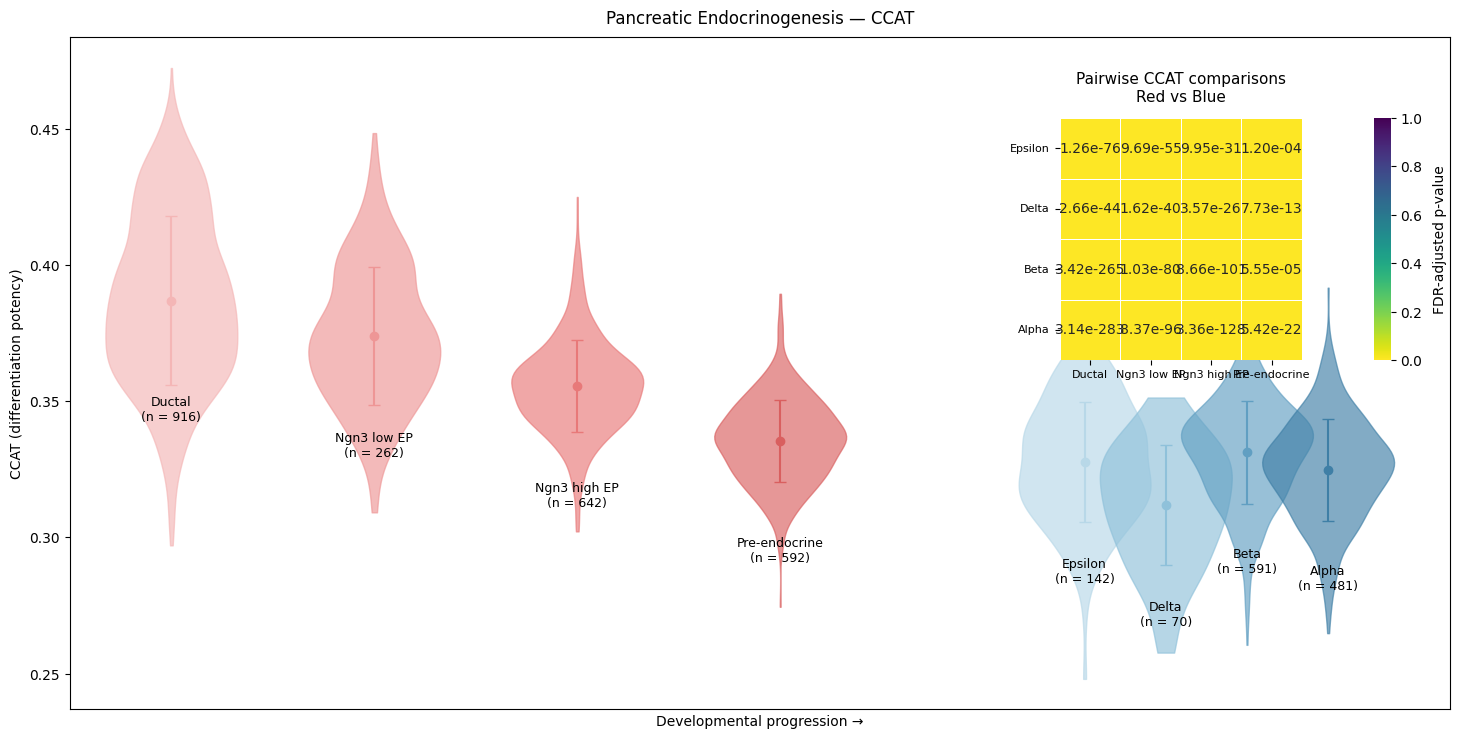

In [4]:
ccat_groups = {
    name: cells.loc[cells["clusters"] == name, "CCAT"].dropna().values
    for name in cluster
}

ccat_means = {name: np.mean(v) for name, v in ccat_groups.items() if len(v) > 0}
ccat_sd = {name: np.std(v, ddof=1) for name, v in ccat_groups.items() if len(v) > 0}
cell_counts = {name: len(v) for name, v in ccat_groups.items()}

x = {
    "Ductal": 0.0, "Ngn3 low EP": 1.0, "Ngn3 high EP": 2.0, "Pre-endocrine": 3.0,
    "Epsilon": 4.5, "Delta": 4.9, "Beta": 5.3, "Alpha": 5.7,
}

fig, ax = plt.subplots(figsize=(15, 8))

for name in cluster:
    if name not in ccat_groups or len(ccat_groups[name]) == 0:
        continue
    vp = ax.violinplot(
        ccat_groups[name], positions=[x[name]], widths=0.65,
        showmeans=False, showmedians=False, showextrema=False
    )
    for body in vp["bodies"]:
        body.set_facecolor(colors[name])
        body.set_edgecolor(colors[name])
        body.set_alpha(0.65)

for name in cluster:
    if name not in ccat_means:
        continue
    ax.errorbar(
        x[name], ccat_means[name], yerr=ccat_sd[name], fmt="o",
        color=colors[name], ecolor=colors[name], capsize=4,
        markersize=6, linewidth=1.5, zorder=5
    )

for name in cluster:
    if name not in ccat_means:
        continue
    ax.text(
        x[name], ccat_means[name] - 0.035, f"{name}\n(n = {cell_counts[name]})",
        ha="center", va="top", fontsize=9
    )

ax.set_xlim(-0.5, 6.3)
ax.set_xticks([])
ax.set_xlabel("Developmental progression →")
ax.set_ylabel("CCAT (differentiation potency)")
ax.set_title("Pancreatic Endocrinogenesis — CCAT", pad=10)

heatmap_ax = ax.inset_axes([0.67, 0.52, 0.27, 0.36])
cbar_ax = ax.inset_axes([0.945, 0.52, 0.012, 0.36])

sns.heatmap(
    pairwise_4x4, annot=True, fmt=".2e", cmap="viridis_r", vmin=0, vmax=1,
    linewidths=0.5, square=True, cbar=True, cbar_ax=cbar_ax, ax=heatmap_ax
)

heatmap_ax.set_title("Pairwise CCAT comparisons\nRed vs Blue", fontsize=11, pad=12)
heatmap_ax.set_xlabel("")
heatmap_ax.set_ylabel("")
heatmap_ax.tick_params(axis="x", rotation=0, labelsize=8)
heatmap_ax.tick_params(axis="y", rotation=0, labelsize=8)
cbar_ax.set_ylabel("FDR-adjusted p-value", rotation=90, labelpad=8)

plt.subplots_adjust(left=0.05, right=0.97, top=0.92, bottom=0.08)
save_figure(fig, 'panel01_ccat_violin_and_pairwise_heatmap')
plt.show()

## ID score across cell types

Pearson r  = 0.9167, p = 1.3554e-03
Spearman ρ = 1.0000, p = 0.0000e+00


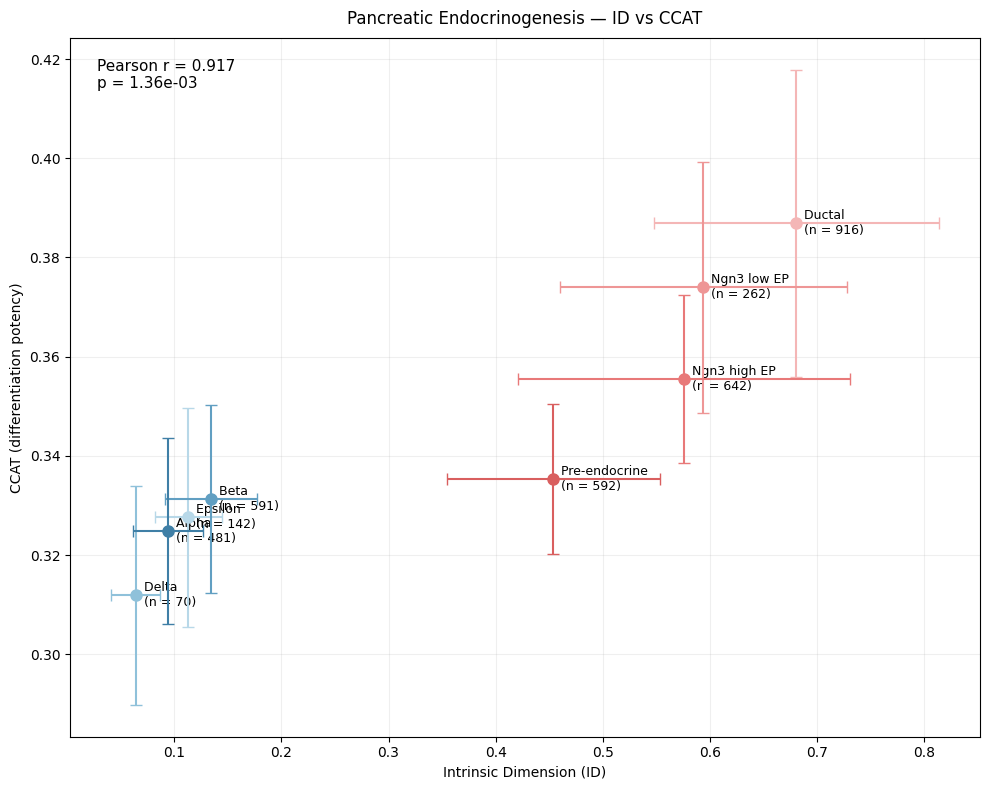

In [5]:
ccat_summary = pd.DataFrame({
    "clusters": list(ccat_means.keys()),
    "CCAT": list(ccat_means.values()),
    "CCAT_SD": [ccat_sd[name] for name in ccat_means],
    "n": [cell_counts[name] for name in ccat_means],
})

plot_data = id_summary.merge(ccat_summary, on="clusters", how="inner")
plot_data["clusters"] = pd.Categorical(plot_data["clusters"], categories=cluster, ordered=True)
plot_data = plot_data.sort_values("clusters").reset_index(drop=True)

pearson_r, pearson_p = pearsonr(plot_data["ID"], plot_data["CCAT"])
spearman_r, spearman_p = spearmanr(plot_data["ID"], plot_data["CCAT"])
print(f"Pearson r  = {pearson_r:.4f}, p = {pearson_p:.4e}")
print(f"Spearman ρ = {spearman_r:.4f}, p = {spearman_p:.4e}")

fig, ax = plt.subplots(figsize=(10, 8))

for _, row in plot_data.iterrows():
    name = row["clusters"]
    ax.errorbar(
        row["ID"], row["CCAT"], xerr=row["SD"], yerr=row["CCAT_SD"],
        fmt="o", color=colors[name], ecolor=colors[name], capsize=4,
        markersize=8, linewidth=1.5, zorder=5
    )
    ax.text(
        row["ID"], row["CCAT"], f"  {name}\n  (n = {row['n']})",
        ha="left", va="center", fontsize=9
    )

ax.text(
    0.03, 0.97, f"Pearson r = {pearson_r:.3f}\np = {pearson_p:.2e}\n",
    transform=ax.transAxes, ha="left", va="top", fontsize=11
)

ax.set_xlabel("Intrinsic Dimension (ID)")
ax.set_ylabel("CCAT (differentiation potency)")
ax.set_title("Pancreatic Endocrinogenesis — ID vs CCAT", pad=10)
ax.grid(True, alpha=0.2)

plt.tight_layout()
save_figure(fig, 'panel02_id_vs_ccat_scatter')
plt.show()